In [32]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from glob import glob
import subprocess
import tempfile
from os.path import dirname

In [70]:
sample = "E06_1"

binning_dir = f"/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir"
taxo_dir = f"/gpfs/data/mock_lab/will/mosaic_tmp/taxo_tmpdir"
mapping_folder = f"/gpfs/data/mock_lab/will/mosaic_tmp/coa_to_ma_mapping"
coassembly_folder = f"/gpfs/data/mock_lab/will/mosaic_tmp/coassemblies_tmp"

In [71]:
!ls /gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/*/vamb_coa/umap_vamb.tsv

/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E01_1/vamb_coa/umap_vamb.tsv
/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E01_2/vamb_coa/umap_vamb.tsv
/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E02_1/vamb_coa/umap_vamb.tsv
/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E02_2/vamb_coa/umap_vamb.tsv
/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E03_1/vamb_coa/umap_vamb.tsv
/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E04_1/vamb_coa/umap_vamb.tsv
/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E04_2/vamb_coa/umap_vamb.tsv
/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E04_3/vamb_coa/umap_vamb.tsv
/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E06_1/vamb_coa/umap_vamb.tsv
/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E07_1/vamb_coa/umap_vamb.tsv
/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E07_2/vamb_coa/umap_vamb.tsv
/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E09_1/vamb_coa/umap_vamb.tsv
/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E11_1/vamb_coa/umap_vamb.tsv

In [72]:
df_umap_coords = pd.read_csv(f"{binning_dir}/{sample}/vamb_coa/umap_vamb.tsv", sep = '\t')
df_umap_coords['sample'] = df_umap_coords.contig_id.apply(lambda x: x.split('_')[0])
df_umap_coords = df_umap_coords.rename(columns = {"contig_id":"coa_contig_id"})
df_umap_coords.head()

,coa_contig_id,umap_0,umap_1,sample
0,k127_96672,4.004841,3.857601,k127
1,k127_2416776,15.342813,4.707466,k127
2,k127_2803460,10.485723,3.471411,k127
3,k127_3093473,2.812544,18.086576,k127
4,k127_1063385,10.825782,2.453180,k127


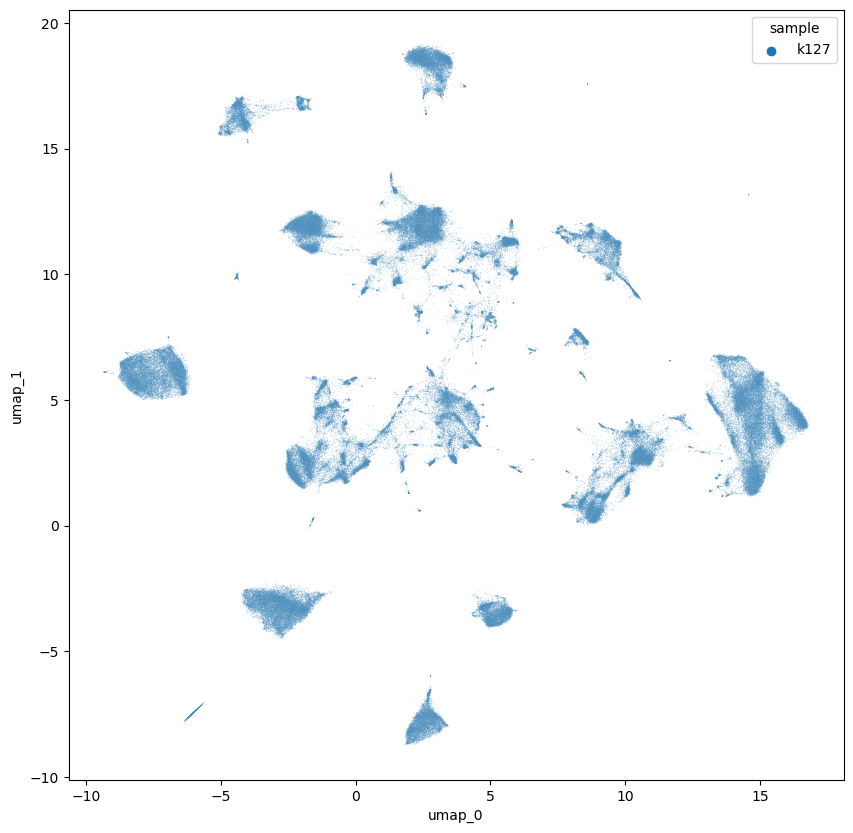

In [73]:
plt.figure(figsize = (10, 10))
ax = sns.scatterplot(
    data = df_umap_coords, 
    x = 'umap_0', 
    y = 'umap_1', 
    s = 0.25, 
    hue = 'sample',
    alpha = 0.5
)

In [74]:
df_contigs = pd.read_csv(
    f"{mapping_folder}/{sample}.mapping.tsv", 
    sep = '\t', 
    names = ["coa_contig_id", "contig_id", "score"]
)

df_contigs['sample'] = df_contigs.contig_id.apply(lambda x: x.split("_")[0])

df_contigs['score_max'] = df_contigs.groupby('coa_contig_id')['score'].transform(max)

df_contigs = df_contigs[df_contigs.score == df_contigs.score_max]

df_contigs = df_contigs.loc[df_contigs[['coa_contig_id', 'score']].drop_duplicates().index]

df_contigs = df_contigs.drop(columns = ["score", "score_max"])

In [60]:
single_samples = list(set(df_contigs['sample']))

def make_taxo_df(sample_id):
    df = pd.read_csv(f"{taxo_dir}/{sample_id}/{sample_id}.faa.mms2lca", sep = '\t')
    df['sample'] = sample_id
    df['contig_id'] = df['sample'] + '_' + df['contig_id']
    return df

df_taxo = pd.concat(
    make_taxo_df(s) for s in single_samples
)

df = pd.merge(
    df_contigs, 
    df_taxo, 
    on = ['contig_id', 'sample'],
    how = 'left'
).fillna("Unknown")


favourite_groups = [
    "Bacillariophyta", 
    "Nucleocytoviricota", 
    "Mamiellophyceae",
    "Dinophyceae",
    "Metazoa",
    "Cryptophyceae",
    "Haptophyta", 
    "Chlorophyta", 
    "Euglenozoa",
    "Ciliophora",
    "Labyrinthulomycetes", 
    "Chrysophyceae", 
    "Choanoflagellata", 
    "Microbotryomycetes", 
    "Amoebozoa", 
    "Ochrophyta", 
    "Chytridiomycota"
]


def simplify_name(row):
    if row.superkingdom in ["Bacteria", "Archaea"]:
        return "Prokaryota"
    
    if row.superkingdom == "Unknown":
        if row['name'] == "Viruses":
            return "Viruses"
        return "Unknown"
    
    for x in favourite_groups:
        if x in row.lineage:
            return x

    if row.superkingdom == "Virus":
        return "Viruses"
    
    return row.superkingdom
    
    
df['name_simple'] = df.apply(simplify_name, axis = 1)

df['euk_unk'] = df.name_simple.isin(["Unknown", "Eukaryota"])

In [61]:
df = pd.merge(
    df_umap_coords, 
    df, 
    on = 'coa_contig_id', 
    how = 'left'
).fillna("None")

In [62]:
mbins = pd.DataFrame([x.split("\t") for x in subprocess.run(
    f"grep -H '>' {binning_dir}/{sample}/metabat_coa/*.fa | cut -f 10 -d '/' | sed 's|.fa:>|\t|g'", 
    capture_output = True, 
    shell = True
).stdout.decode("ASCII").strip().split("\n")], columns = ["metabat_id", "coa_contig_id"])

df = pd.merge(
    df, 
    mbins, 
    on = 'coa_contig_id', 
    how = 'left'
).fillna("None")

vbins = pd.DataFrame([x.split("\t") for x in subprocess.run(
    f"grep -H '>' {binning_dir}/{sample}/vamb_coa/*bins/*.fna | cut -f 1 -d ' ' | cut -f 11 -d '/' | sed 's|.fna:>|\t|g'", 
    capture_output = True, 
    shell = True
).stdout.decode("ASCII").strip().split("\n")], columns = ["vamb_id", "coa_contig_id"])

df = pd.merge(
    df, 
    vbins, 
    on = 'coa_contig_id', 
    how = 'left'
).fillna("None")

vacbins = pd.read_csv(
    f"{binning_dir}/{sample}/vamb_coa/vacuum_bins.tsv",
    sep = '\t'
).rename(
    columns = {'contig_id':'coa_contig_id'}
)

df = pd.merge(
    df, 
    vacbins, 
    on = 'coa_contig_id', 
    how = 'left'
).fillna("None")

In [63]:
#plt.figure(figsize = (10, 10))
#ax = sns.scatterplot(
#    data = df, 
#    x = 'umap_0', 
#    y = 'umap_1', 
#    s = 0.25, 
#    hue = 'metabat_id',
#    alpha = 0.5
#)
#sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))

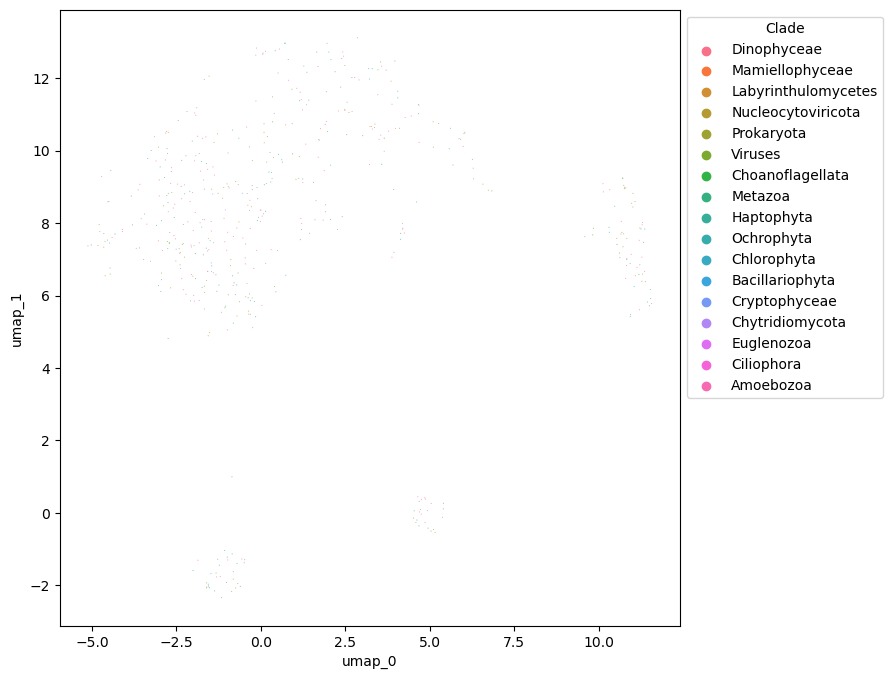

In [64]:
plt.figure(figsize = (8, 8))
ax = sns.scatterplot(
    data = df[~df.name_simple.isin(["Unknown", "Eukaryota", "None"])],
    x = 'umap_0', 
    y = 'umap_1', 
    s = 0.5, 
    hue = 'name_simple',
    alpha = 0.85
)

plt.legend(title='Clade')
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
#plt.savefig(f"/gpfs/home/qcf21tku/scratch/refine_chap/svgs/{sample}_umap_image.png")

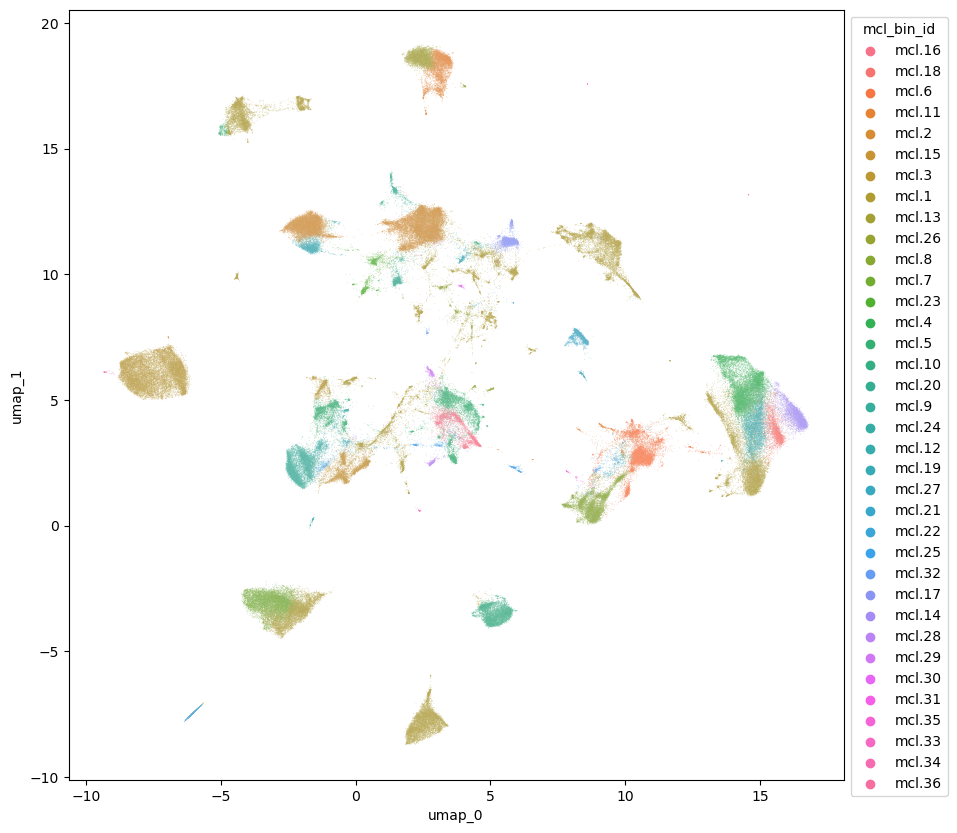

In [12]:
plt.figure(figsize = (10, 10))
ax = sns.scatterplot(
    data = df, 
    x = 'umap_0', 
    y = 'umap_1', 
    s = 0.25, 
    hue = 'mcl_bin_id',
    alpha = 0.5
)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))

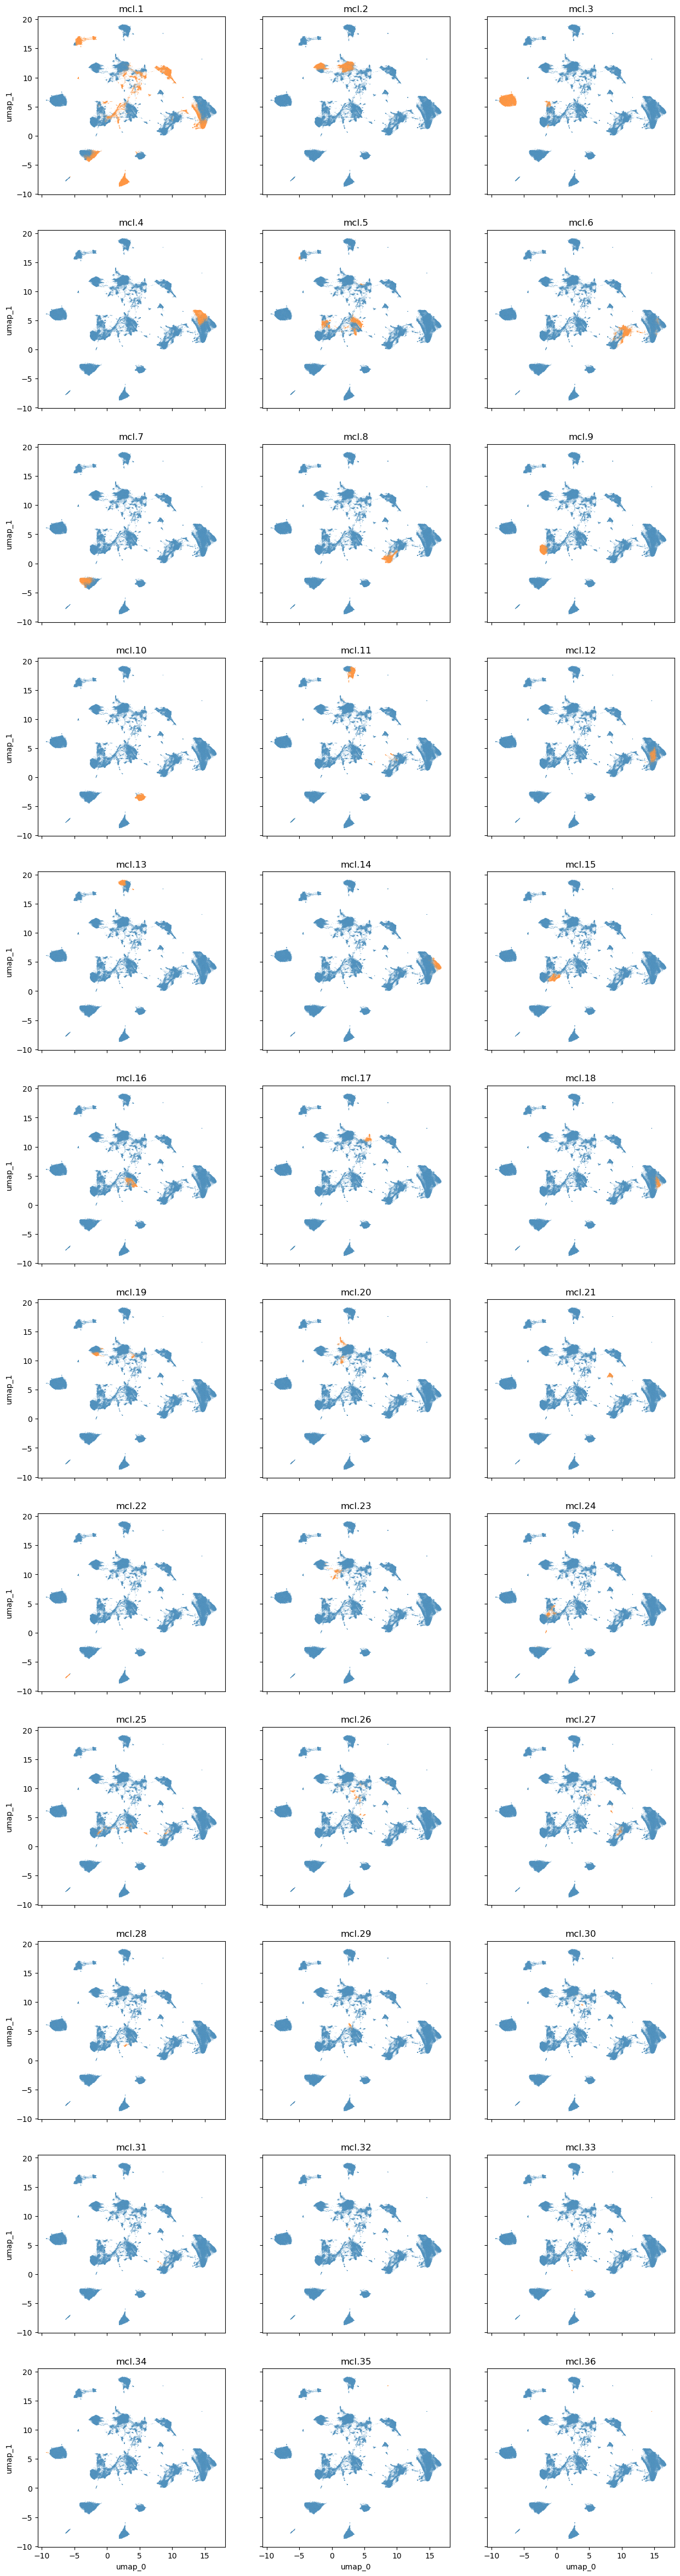

In [13]:
N = len(set(df.mcl_bin_id))

n,m = (int(N/3) if N%3 == 0 else int(N/3) + 1),3

fig, axes = plt.subplots(n,m, figsize = (5 * m, 5 * n), sharex = True, sharey = True)
for i in range(0, n):
    for j in range(1, m + 1):
        df['target_mag'] = (df.mcl_bin_id == f"mcl.{m * i + j}")
        sns.scatterplot(
            ax = axes[i, j-1], 
            data = df, 
            x = 'umap_0', 
            y = 'umap_1', 
            s = 0.25, 
            hue = 'target_mag',
            alpha = 0.5,    
        )
        axes[i,j - 1].set_title(f"mcl.{m * i + j}")
        axes[i, j-1].get_legend().remove()

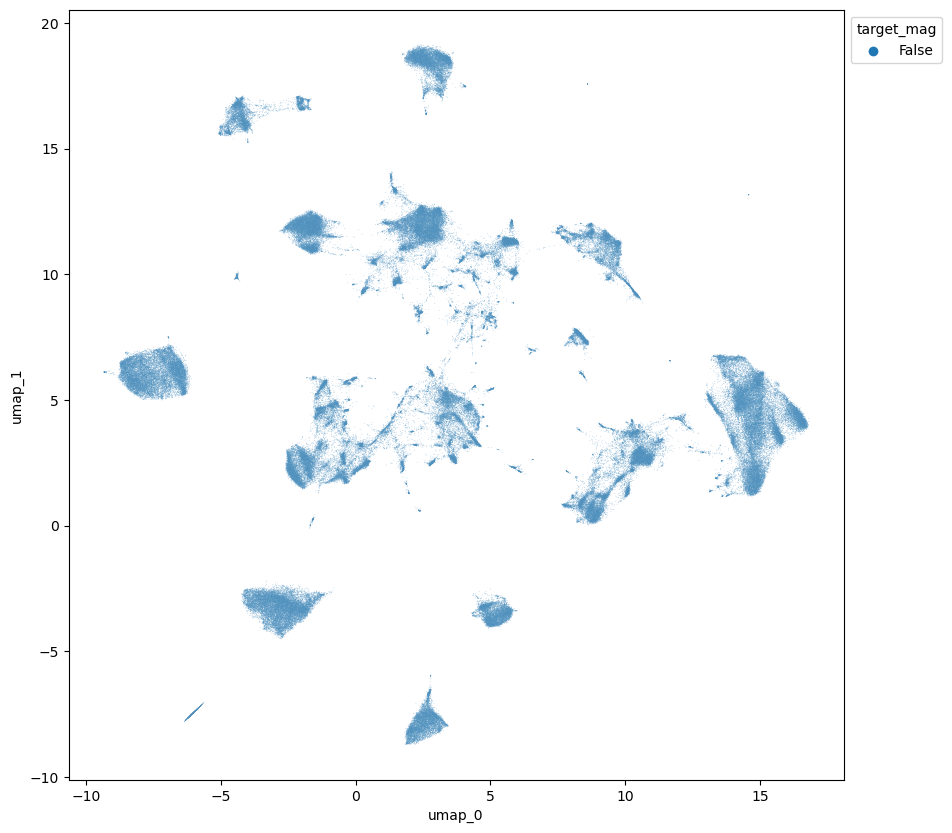

In [14]:
df['target_mag'] = (df.mcl_bin_id.isin(["mcl.2"]) & (df.umap_0 > 10))

plt.figure(figsize = (10, 10))
ax = sns.scatterplot(
    data = df, 
    x = 'umap_0', 
    y = 'umap_1', 
    s = 0.25, 
    hue = 'target_mag',
    alpha = 0.5
)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))

In [15]:
! cat {binning_dir}/{sample}/all_bins_coa_auto_eukcc/eukcc.csv

! wc -m {binning_dir}/{sample}/all_bins_coa_auto/*.fna

bin	completeness	contamination	ncbi_lng
   6270001 /gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E06_1/all_bins_coa_auto/mbat_coa.11.fna
  35369283 /gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E06_1/all_bins_coa_auto/mbat_coa.13.fna
  40566833 /gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E06_1/all_bins_coa_auto/mbat_coa.1.fna
  24146242 /gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E06_1/all_bins_coa_auto/mbat_coa.20.fna
  29598101 /gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E06_1/all_bins_coa_auto/mbat_coa.23.fna
  20405083 /gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E06_1/all_bins_coa_auto/mbat_coa.30.fna
  47036478 /gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E06_1/all_bins_coa_auto/mbat_coa.34.fna
   8807894 /gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E06_1/all_bins_coa_auto/mbat_coa.35.fna
   5503530 /gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E06_1/all_bins_coa_auto/mbat_coa.38.fna
  21851117 /gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E06_1/all_b

In [16]:
! wc -m {binning_dir}/{sample}/all_bins_coa_manual/*.fna

 32058565 /gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E06_1/all_bins_coa_manual/mcl.11.13.split_1_v1.fna
 20482044 /gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E06_1/all_bins_coa_manual/mcl.1.5.split_1_v1.fna
 59177063 /gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E06_1/all_bins_coa_manual/mcl.1.7.split_2_v1.fna
 54324878 /gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E06_1/all_bins_coa_manual/mcl.1.split_1_v1.fna
 54324878 /gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E06_1/all_bins_coa_manual/mcl.1.split_2_v1.fna
 28698998 /gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E06_1/all_bins_coa_manual/mcl.1.split_3_v1.fna
 51609747 /gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E06_1/all_bins_coa_manual/mcl.2.split_1_v1.fna
 46760445 /gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E06_1/all_bins_coa_manual/mcl.2.split_2_v1.fna
 60951356 /gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E06_1/all_bins_coa_manual/mcl.3.split_1_v1.fna
105503182 /gpfs/data/mock_lab/will/mosaic_tmp/b

In [17]:
#Below here is done on a per-sample basis... Don't rerun!

In [18]:
df[
    (df.mcl_bin_id.isin(["mcl.2"]) & (df.umap_0 > 10))
].groupby(
    ["name_simple"]
).count().sort_values(
    'coa_contig_id', 
    ascending = False
)

,coa_contig_id,umap_0,umap_1,sample_x,contig_id,sample_y,taxid,superkingdom,lineage,taxon,name,euk_unk,metabat_id,vamb_id,mcl_bin_id,target_mag
name_simple,,,,,,,,,,,,,,,,


In [82]:
#df[(df.mcl_bin_id == "mcl.2") & (df.umap_0 > 10)]

In [83]:
def extract_contigs(df, path_to_contigs, output_path, contig_column = 'coa_contig_id'):
    """
    Extract contigs based on a 'contig_id' column in a DataFrame.

    Args:
        df (pd.DataFrame): The DataFrame containing contig IDs.
        contig_column (str): The name of the column with contig IDs.
        path_to_contigs (str): Path to the file containing all contigs (FASTA).
        output_path (str): Path to save the extracted contigs (FASTA).
    """
    # Ensure the contig_column exists
    if contig_column not in df.columns:
        raise ValueError(f"Column '{contig_column}' not found in DataFrame.")

    # Extract unique contig IDs
    contig_ids = df[contig_column].drop_duplicates().tolist()

    # Use a temporary file to hold contig IDs
    with tempfile.NamedTemporaryFile(mode="w", delete=True) as tmpfile:
        for contig_id in contig_ids:
            tmpfile.write(f"{contig_id}\n")
        tmpfile.flush()  # Ensure all data is written to the file before reading

        # Run seqkit grep to extract matching contigs
        try:
            subprocess.run(["mkdir", "-p", dirname(output_path)])
            subprocess.run(
                [
                    "seqkit", "grep",
                    "-f", tmpfile.name,
                    "-o", output_path,
                    path_to_contigs
                ],
                check=True
            )
            print(f"Contigs extracted successfully to {output_path}")
        except subprocess.CalledProcessError as e:
            print(f"Error running seqkit grep: {e}")



In [84]:
#extract_contigs(
#    df[(df.mcl_bin_id.isin(["mcl.2"]) & (df.umap_0 > 10))], 
#    f"{coassembly_folder}/{sample}/megahit/final.contigs.fa", 
#    f"{binning_dir}/{sample}/all_bins_coa_manual/mcl.2.split_1_v1.fna"
#)